# 02 — EDA, Label, dan Split

**Tujuan:** (1) membuat statistik dataset untuk Bab III-B, (2) membentuk matriks label (difficulty + top-15 topik), (3) membuat **satu split tetap** yang dipakai semua notebook modeling.

**Input:** `data_clean.csv` (dari Notebook 01)

**Output:**
- `labels.csv` — label difficulty dan 15 kolom topik biner
- `split.csv` — kolom `set` (train/test) dan `fold` (0-4 untuk train, -1 untuk test)
- `split_meta.json` — seed terpilih dan parameter split (untuk Bab III-F)
- `tables/*.csv` dan `figures/*.png` — bahan tabel dan gambar paper

**Keputusan desain yang diterapkan di sini:**
- Label topik = **top-15 tag** terbanyak. Soal tanpa satu pun tag top-15 tetap dipakai (baris all-zero).
- Test set 20%, dipakai **sekali** di akhir. CV 5-fold hanya pada 80% sisanya.
- Stratifikasi **gabungan** difficulty + topik, sehingga split yang sama adil untuk kedua target.

> Jangan jalankan ulang bagian split setelah Notebook 03-06 dimulai. Split harus tetap sama.

## 1. Import & Konfigurasi

!pip install iterative-stratification

In [1]:
import json
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
except ImportError:
    # Jalankan sekali: pip install iterative-stratification
    raise ImportError('Install dulu: pip install iterative-stratification')

DATA_PATH = r'D:\TrioSetiawan\course\kuliah\s3\text_mining\uts_leetcode\01_preprocessing\output\data_clean.csv'
SEED = 42                        # seed umum (split memakai pencarian seed, lihat bagian 9)
TOP_K = 15
N_FOLDS = 5
TEST_FRACTION_FOLDS = 5          # 1/5 = 20% test
DIFF_ORDER = ['Easy', 'Medium', 'Hard']

os.makedirs('tables', exist_ok=True)
os.makedirs('figures', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight'})

## 2. Load Data

In [2]:
df = pd.read_csv(DATA_PATH)
df['category'] = df['category'].fillna('')

# Urutan baris harus menurut id (konvensi seluruh notebook)
assert df['id'].is_unique
assert df['id'].is_monotonic_increasing, 'data_clean.csv harus terurut menurut id'

print('Jumlah soal:', len(df))
df[['id', 'title', 'difficulty', 'category', 'n_tokens_before', 'n_tokens_after']].head()

Jumlah soal: 3256


,id,title,difficulty,category,n_tokens_before,n_tokens_after
0,1,Two Sum,Easy,Array; Hash Table,102,43
1,2,Add Two Numbers,Medium,Linked List; Math; Recursion,103,46
2,3,Longest Substring Without Repeating Characters,Medium,Hash Table; String; Sliding Window,93,38
3,4,Median of Two Sorted Arrays,Hard,Array; Binary Search; Divide and Conquer,69,32
4,5,Longest Palindromic Substring,Medium,Two Pointers; String; Dynamic Programming; Man...,41,17


## 3. Distribusi Difficulty

            count  percent
difficulty                
Easy          833     25.6
Medium       1645     50.5
Hard          778     23.9


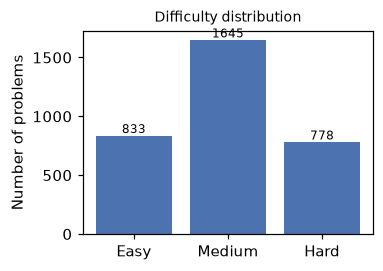

In [3]:
diff_counts = df['difficulty'].value_counts().reindex(DIFF_ORDER)
diff_table = pd.DataFrame({'count': diff_counts, 'percent': (diff_counts / len(df) * 100).round(1)})
diff_table.to_csv('tables/difficulty_distribution.csv')
print(diff_table)

fig, ax = plt.subplots(figsize=(3.4, 2.4))
ax.bar(diff_table.index, diff_table['count'], color='#4c72b0')
for i, v in enumerate(diff_table['count']):
    ax.text(i, v, str(v), ha='center', va='bottom', fontsize=8)
ax.set_ylabel('Number of problems')
ax.set_title('Difficulty distribution', fontsize=9)
fig.savefig('figures/difficulty_distribution.png')
plt.show()

## 4. Distribusi Topik

Satu soal bisa punya beberapa tag (multilabel). Pertama lihat seluruh tag, lalu pilih top-15.

In [4]:
df['tag_list'] = df['category'].apply(lambda s: [t for t in s.split('; ') if t])

all_tag_counts = pd.Series([t for tags in df['tag_list'] for t in tags]).value_counts()
n_tags_per_problem = df['tag_list'].apply(len)

print('Jumlah tag unik         :', len(all_tag_counts))
print('Tag per soal (mean/med) :', round(n_tags_per_problem.mean(), 2), '/', n_tags_per_problem.median())
print('Soal tanpa tag apa pun  :', int((n_tags_per_problem == 0).sum()))
print('Tag dengan < 50 soal    :', int((all_tag_counts < 50).sum()), 'dari', len(all_tag_counts))

top_tags = list(all_tag_counts.head(TOP_K).index)
top_table = pd.DataFrame({
    'count': all_tag_counts.head(TOP_K),
    'percent_of_problems': (all_tag_counts.head(TOP_K) / len(df) * 100).round(1),
})
top_table.to_csv('tables/top15_topics.csv')
top_table

Jumlah tag unik         : 172
Tag per soal (mean/med) : 3.28 / 3.0
Soal tanpa tag apa pun  : 80
Tag dengan < 50 soal    : 138 dari 172


,count,percent_of_problems
Array,1909,58.6
String,767,23.6
Hash Table,703,21.6
Math,609,18.7
Dynamic Programming,594,18.2
Sorting,459,14.1
Greedy,432,13.3
Binary Search,297,9.1
Depth-First Search,263,8.1
Bit Manipulation,259,8.0


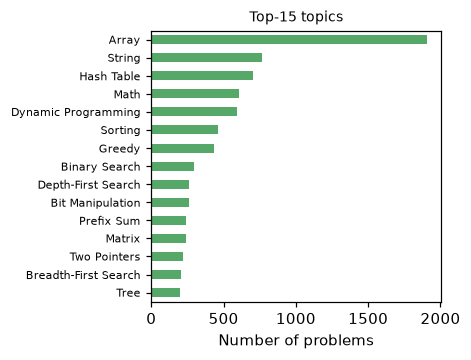

In [5]:
fig, ax = plt.subplots(figsize=(3.4, 3.2))
top_table['count'][::-1].plot.barh(ax=ax, color='#55a868')
ax.set_xlabel('Number of problems')
ax.set_title('Top-15 topics', fontsize=9)
ax.tick_params(axis='y', labelsize=7)
fig.savefig('figures/top15_topics.png')
plt.show()

## 5. Matriks Label

Kolom topik: `topic_<nama>` (biner). Label difficulty: `difficulty` dan `difficulty_id` (Easy=0, Medium=1, Hard=2).

Pemilihan top-15 memakai frekuensi tag, **bukan fitur teks**, jadi tidak menimbulkan kebocoran.

In [6]:
def topic_col(name):
    return 'topic_' + re.sub(r'[^a-z0-9]+', '_', name.lower()).strip('_')

topic_cols = [topic_col(t) for t in top_tags]
assert len(set(topic_cols)) == TOP_K, 'nama kolom topik bentrok'

Y_topic = np.array([[int(t in tags) for t in top_tags] for tags in df['tag_list']], dtype=int)
labels = pd.DataFrame(Y_topic, columns=topic_cols)
labels.insert(0, 'difficulty_id', df['difficulty'].map({d: i for i, d in enumerate(DIFF_ORDER)}).values)
labels.insert(0, 'difficulty', df['difficulty'].values)
labels.insert(0, 'id', df['id'].values)

assert labels['difficulty_id'].notna().all()

# Statistik multilabel untuk Bab III-B
row_sum = Y_topic.sum(axis=1)
n_zero = int((row_sum == 0).sum())
stats = {
    'n_problems': len(df),
    'n_labels': TOP_K,
    'label_cardinality': round(float(row_sum.mean()), 3),            # rata-rata label per soal
    'label_density': round(float(row_sum.mean() / TOP_K), 3),
    'n_all_zero_rows': n_zero,
    'pct_all_zero_rows': round(n_zero / len(df) * 100, 2),
}
print(json.dumps(stats, indent=2))
pd.Series(stats).to_csv('tables/multilabel_stats.csv', header=['value'])

{
  "n_problems": 3256,
  "n_labels": 15,
  "label_cardinality": 2.271,
  "label_density": 0.151,
  "n_all_zero_rows": 233,
  "pct_all_zero_rows": 7.16
}


**Cek:** jika `pct_all_zero_rows` kecil (sekitar < 5%), cukup dilaporkan di paper. Jika besar, pertimbangkan ulang apakah baris all-zero tetap dipakai.

## 6. Difficulty per Topik

Seberapa miring sebaran difficulty di tiap topik. Berguna untuk RQ4: jika sebaran difficulty hampir sama di semua topik, teks topik sendiri tidak membantu menebak difficulty.

In [7]:
rows = []
for name, col in zip(top_tags, topic_cols):
    sub = labels.loc[labels[col] == 1, 'difficulty']
    share = sub.value_counts(normalize=True).reindex(DIFF_ORDER).fillna(0) * 100
    rows.append({'topic': name, 'n': len(sub), **{f'{d}_%': round(share[d], 1) for d in DIFF_ORDER}})
topic_diff = pd.DataFrame(rows).set_index('topic')
topic_diff.loc['(all problems)'] = [len(df)] + [round(v, 1) for v in (diff_table['percent'].values)]
topic_diff.to_csv('tables/difficulty_by_topic.csv')
topic_diff

,n,Easy_%,Medium_%,Hard_%
topic,,,,
Array,1909.0,21.2,52.3,26.5
String,767.0,29.9,47.8,22.3
Hash Table,703.0,24.2,55.6,20.2
Math,609.0,26.4,46.3,27.3
Dynamic Programming,594.0,2.2,46.6,51.2
Sorting,459.0,19.4,57.1,23.5
Greedy,432.0,11.3,67.4,21.3
Binary Search,297.0,8.8,52.2,39.1
Depth-First Search,263.0,13.3,56.7,30.0


## 7. Panjang Teks

             count   mean   std   min    25%    50%    75%    max
difficulty                                                       
Easy         833.0  139.4  64.4  21.0   92.0  127.0  175.0  511.0
Medium      1645.0  179.0  86.2  26.0  117.0  165.0  226.0  715.0
Hard         778.0  208.1  97.9  32.0  135.0  191.0  268.0  640.0


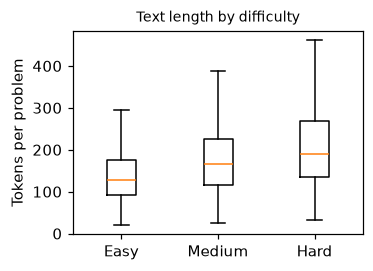

In [8]:
len_by_diff = df.groupby('difficulty')['n_tokens_before'].describe().reindex(DIFF_ORDER).round(1)
len_by_diff.to_csv('tables/token_length_by_difficulty.csv')
print(len_by_diff)

fig, ax = plt.subplots(figsize=(3.4, 2.4))
ax.boxplot([df.loc[df['difficulty'] == d, 'n_tokens_before'] for d in DIFF_ORDER],
           showfliers=False)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(DIFF_ORDER)
ax.set_ylabel('Tokens per problem')
ax.set_title('Text length by difficulty', fontsize=9)
fig.savefig('figures/token_length_by_difficulty.png')
plt.show()

## 8. Simpan Label

Seluruh baris sejajar dengan `data_clean.csv` (terurut menurut `id`).

In [9]:
labels.to_csv('labels.csv', index=False)
print('Tersimpan labels.csv', labels.shape)
labels.head()

Tersimpan labels.csv (3256, 18)


,id,difficulty,difficulty_id,topic_array,topic_string,topic_hash_table,topic_math,topic_dynamic_programming,topic_sorting,topic_greedy,topic_binary_search,topic_depth_first_search,topic_bit_manipulation,topic_prefix_sum,topic_matrix,topic_two_pointers,topic_breadth_first_search,topic_tree
0,1,Easy,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0
1,2,Medium,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
2,3,Medium,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0
3,4,Hard,2,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0
4,5,Medium,1,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0


## 9. Split Train / Test + Fold CV

Dua langkah, keduanya multilabel-stratified:
1. 5-fold pertama dibentuk pada seluruh data; satu fold diambil sebagai **test (20%)**.
2. Sisa 80% dibagi lagi menjadi **5 fold CV** untuk tuning.

Matriks stratifikasi = one-hot difficulty (3) + 15 topik + 1 kolom penanda baris all-zero, supaya baris all-zero ikut tersebar merata.

In [10]:
diff_onehot = np.eye(3, dtype=int)[labels['difficulty_id'].values]
zero_flag = (Y_topic.sum(axis=1) == 0).astype(int)[:, None]
strat = np.hstack([diff_onehot, Y_topic, zero_flag])
N_SEEDS = 50


def split_deviation(strat_a, strat_b):
    # selisih proporsi (poin persen) terbesar antar dua himpunan pada semua kolom stratifikasi
    return float(np.abs(strat_a.mean(axis=0) - strat_b.mean(axis=0)).max() * 100)


# Langkah 1: test 20%. Coba beberapa seed, pilih yang paling seimbang.
best = None
for sd in range(N_SEEDS):
    outer = MultilabelStratifiedKFold(n_splits=TEST_FRACTION_FOLDS, shuffle=True, random_state=sd)
    tr, te = next(iter(outer.split(np.zeros(len(df)), strat)))
    dev = split_deviation(strat[tr], strat[te])
    if best is None or dev < best[0]:
        best = (dev, sd, tr, te)
outer_dev, SEED_OUTER, train_idx, test_idx = best
print(f'Seed test terpilih: {SEED_OUTER} (selisih proporsi terbesar {outer_dev:.2f} poin persen)')

# Langkah 2: 5-fold CV di data latih. Pilih seed dengan fold paling seimbang.
strat_train = strat[train_idx]
best = None
for sd in range(N_SEEDS):
    inner = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=sd)
    parts = [val for _, val in inner.split(np.zeros(len(train_idx)), strat_train)]
    dev = max(split_deviation(strat_train[p], strat_train) for p in parts)
    if best is None or dev < best[0]:
        best = (dev, sd, parts)
inner_dev, SEED_INNER, parts = best
print(f'Seed fold CV terpilih: {SEED_INNER} (selisih proporsi fold terbesar {inner_dev:.2f} poin persen)')

fold = np.full(len(df), -1, dtype=int)
for k, val_local in enumerate(parts):
    fold[train_idx[val_local]] = k

split = pd.DataFrame({'id': df['id'].values})
split['set'] = np.where(fold == -1, 'test', 'train')
split['fold'] = fold

print()
print(split['set'].value_counts().to_string())
print('Ukuran tiap fold CV:', split.loc[split['set'] == 'train', 'fold'].value_counts().sort_index().tolist())

Seed test terpilih: 26 (selisih proporsi terbesar 0.12 poin persen)
Seed fold CV terpilih: 17 (selisih proporsi fold terbesar 0.52 poin persen)

set
train    2605
test      651
Ukuran tiap fold CV: [520, 519, 521, 525, 520]


**Catatan:** stratifikasi iteratif memprioritaskan label langka, sehingga label sangat umum seperti Array kadang bergeser beberapa poin persen antara train dan test. Karena itu beberapa seed dicoba (0-49) dan dipilih yang paling seimbang. Seed terpilih dicatat di `split_meta.json` dan sebaiknya disebut di paper (Bab III-F).

## 10. Verifikasi Split

Pastikan tidak ada kebocoran dan proporsi kelas terjaga.

In [11]:
# 1) Tidak ada tumpang tindih & semua baris terpakai
assert set(train_idx).isdisjoint(set(test_idx))
assert len(train_idx) + len(test_idx) == len(df)
assert (split['fold'][split['set'] == 'train'] >= 0).all()
assert (split['fold'][split['set'] == 'test'] == -1).all()

# 2) Proporsi tiap kolom stratifikasi: train vs test
col_names = DIFF_ORDER + top_tags + ['(all-zero)']
prev_train = strat[train_idx].mean(axis=0) * 100
prev_test = strat[test_idx].mean(axis=0) * 100
check = pd.DataFrame({'train_%': prev_train.round(1), 'test_%': prev_test.round(1)}, index=col_names)
check['abs_diff'] = (check['train_%'] - check['test_%']).abs().round(2)
check.to_csv('tables/split_check.csv')
print('Selisih proporsi terbesar train vs test:', check['abs_diff'].max(), 'poin persen')
print()

# 3) Jumlah positif per label di test dan di tiap fold CV
pos_test = Y_topic[test_idx].sum(axis=0)
pos_fold = np.array([Y_topic[fold == k].sum(axis=0) for k in range(N_FOLDS)])
print('Positif per label di test  (min):', int(pos_test.min()))
print('Positif per label per fold (min):', int(pos_fold.min()))
assert pos_test.min() > 0 and pos_fold.min() > 0, 'ada label tanpa positif di test/fold'

check

Selisih proporsi terbesar train vs test: 0.2 poin persen

Positif per label di test  (min): 40
Positif per label per fold (min): 32


,train_%,test_%,abs_diff
Easy,25.6,25.5,0.1
Medium,50.5,50.5,0.0
Hard,23.9,24.0,0.1
Array,58.6,58.7,0.1
String,23.5,23.7,0.2
Hash Table,21.6,21.7,0.1
Math,18.7,18.7,0.0
Dynamic Programming,18.2,18.3,0.1
Sorting,14.1,14.1,0.0
Greedy,13.3,13.2,0.1


## 11. Simpan Split

In [12]:
split.to_csv('split.csv', index=False)

split_meta = {
    'seed_outer_test': int(SEED_OUTER),
    'seed_inner_cv': int(SEED_INNER),
    'seeds_tried': N_SEEDS,
    'max_prop_diff_train_test_pp': round(outer_dev, 2),
    'max_prop_diff_cv_fold_pp': round(inner_dev, 2),
    'n_total': int(len(df)),
    'n_train': int((split['set'] == 'train').sum()),
    'n_test': int((split['set'] == 'test').sum()),
    'n_cv_folds': N_FOLDS,
    'stratification': 'MultilabelStratifiedKFold on [difficulty one-hot (3) + top-15 topics + all-zero flag]',
    'top_k': TOP_K,
    'topic_names': top_tags,
    'topic_columns': topic_cols,
    'label_stats': stats,
}
with open('split_meta.json', 'w', encoding='utf-8') as f:
    json.dump(split_meta, f, indent=2, ensure_ascii=False)

# Baca ulang & cek sejajar dengan data_clean.csv
chk_split = pd.read_csv('split.csv')
chk_labels = pd.read_csv('labels.csv')
assert (chk_split['id'].values == df['id'].values).all()
assert (chk_labels['id'].values == df['id'].values).all()
print('Tersimpan: labels.csv, split.csv, split_meta.json')
print(chk_split['set'].value_counts().to_dict())

Tersimpan: labels.csv, split.csv, split_meta.json
{'train': 2605, 'test': 651}


## Ringkasan untuk paper (Bab III-B / III-F)

Setelah notebook dijalankan, salin angka-angka berikut dari output:
- jumlah soal dan sebaran difficulty (Tabel difficulty)
- top-15 topik dan jumlahnya (`tables/top15_topics.csv`)
- label cardinality, density, dan persentase baris all-zero
- ukuran train/test, seed terpilih, dan selisih proporsi terbesar